# **Pronóstico del precio de apertura de Bitcoin con Deep Learning**

Comparación de cinco arquitecturas de redes neuronales para series de tiempo (LSTM, GRU, BiLSTM, CNN-LSTM y Transformer) frente a un pronóstico ingenuo (*naive*), con datos diarios de BTC-USD descargados de Yahoo Finance.

**Configuración fija del experimento:** ventana de 60 días, horizonte de 1 día, variables de entrada `Close`, `High`, `Low` y `Open`, variable objetivo `Open`, partición temporal 70/15/15 y RMSE en USD como métrica principal.


In [29]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import time
import datetime

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import (
    Dense, LSTM, GRU, Bidirectional, Input,
    Conv1D, GlobalAveragePooling1D, LayerNormalization,
    MultiHeadAttention, Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
)

import yfinance as yf

# Semilla de reproducibilidad
np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow:", tf.__version__)
df = yf.download('BTC-USD', start='2015-01-01', end='2026-09-19')
df.head()

/tmp/ipykernel_1593/3689533584.py:30: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('BTC-USD', start='2015-01-01', end='2026-09-19')
[*********************100%***********************]  1 of 1 completed

TensorFlow: 2.20.0


Price,Close,High,Low,Open,Volume
Ticker,BTC-USD,BTC-USD,BTC-USD,BTC-USD,BTC-USD
Date,,,,,
2015-01-01,314.248993,320.434998,314.002991,320.434998,8036550
2015-01-02,315.032013,315.838989,313.565002,314.079010,7860650
2015-01-03,281.082001,315.149994,281.082001,314.846008,33054400
2015-01-04,264.195007,287.230011,257.612000,281.145996,55629100
2015-01-05,274.473999,278.341003,265.084015,265.084015,43962800


In [30]:
df = yf.download('BTC-USD', start='2015-01-01', end='2026-09-19')

# Aplanar columnas MultiIndex si las hay
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

df.reset_index(inplace=True)

print(f"Filas    : {len(df)}")
print(f"Columnas : {list(df.columns)}")
df.head()

/tmp/ipykernel_1593/561763886.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download('BTC-USD', start='2015-01-01', end='2026-09-19')
[*********************100%***********************]  1 of 1 completed

Filas    : 4279
Columnas : ['Date', 'Close', 'High', 'Low', 'Open', 'Volume']


Price,Date,Close,High,Low,Open,Volume
0,2015-01-01,314.248993,320.434998,314.002991,320.434998,8036550
1,2015-01-02,315.032013,315.838989,313.565002,314.079010,7860650
2,2015-01-03,281.082001,315.149994,281.082001,314.846008,33054400
3,2015-01-04,264.195007,287.230011,257.612000,281.145996,55629100
4,2015-01-05,274.473999,278.341003,265.084015,265.084015,43962800


In [31]:
df.sort_values(by='Date', ascending=True, inplace=True)
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4279 entries, 0 to 4278
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4279 non-null   datetime64[ns]
 1   Close   4279 non-null   float64       
 2   High    4279 non-null   float64       
 3   Low     4279 non-null   float64       
 4   Open    4279 non-null   float64       
 5   Volume  4279 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 200.7 KB


Price,Date,Close,High,Low,Open,Volume
count,4279,4279.000000,4279.000000,4279.000000,4279.000000,4.279000e+03
mean,2020-11-09 00:00:00.000000256,30294.324453,30867.923470,29650.867504,30276.480045,2.298271e+10
min,2015-01-01 00:00:00,178.102997,211.731003,171.509995,176.897003,7.860650e+06
25%,2017-12-05 12:00:00,4012.076294,4086.394897,3911.084229,4007.700928,3.540447e+09
50%,2020-11-09 00:00:00,16444.626953,16666.863281,15880.706055,16440.222656,1.904344e+10
75%,2023-10-14 12:00:00,51743.324219,52508.619141,50506.982422,51706.775391,3.473853e+10
max,2026-09-18 00:00:00,124752.531250,126198.070312,123196.046875,124752.140625,3.509679e+11
std,NaN,32691.162023,33228.627094,32105.480487,32685.783381,2.274149e+10


# 3. Análisis exploratorio de datos (EDA)

## 3.1 Estructura y valores faltantes

Se verifica el orden cronológico, los tipos de datos y la presencia
de valores faltantes. En series de tiempo financieras es fundamental
que las observaciones estén ordenadas de forma ascendente por fecha
antes de cualquier transformación.

In [32]:
# Ordenar por fecha de forma ascendente
df.sort_values(by='Date', ascending=True, inplace=True)
df.reset_index(drop=True, inplace=True)

print("=== Información general ===")
df.info()
print()
print("=== Valores faltantes ===")
print(df.isnull().sum())

=== Información general ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4279 entries, 0 to 4278
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    4279 non-null   datetime64[ns]
 1   Close   4279 non-null   float64       
 2   High    4279 non-null   float64       
 3   Low     4279 non-null   float64       
 4   Open    4279 non-null   float64       
 5   Volume  4279 non-null   int64         
dtypes: datetime64[ns](1), float64(4), int64(1)
memory usage: 200.7 KB

=== Valores faltantes ===
Price
Date      0
Close     0
High      0
Low       0
Open      0
Volume    0
dtype: int64


## 3.2 Estadísticos descriptivos

Los estadísticos descriptivos permiten entender la escala de cada
variable. El precio del Bitcoin ha variado desde unos pocos cientos
de dólares en 2015 hasta más de 100 000 USD en 2024–2026, lo que
genera una distribución muy asimétrica con mínimos y máximos muy
alejados entre sí.

In [33]:
df[['Open', 'High', 'Low', 'Close']].describe().round(2)

Price,Open,High,Low,Close
count,4279.00,4279.00,4279.00,4279.00
mean,30276.48,30867.92,29650.87,30294.32
std,32685.78,33228.63,32105.48,32691.16
min,176.90,211.73,171.51,178.10
25%,4007.70,4086.39,3911.08,4012.08
50%,16440.22,16666.86,15880.71,16444.63
75%,51706.78,52508.62,50506.98,51743.32
max,124752.14,126198.07,123196.05,124752.53


## 3.3 Visualización de la serie temporal

Se grafica la evolución del precio de cierre y el volumen de
transacciones a lo largo del tiempo. Esta gráfica muestra claramente
la tendencia alcista de largo plazo, los ciclos de bull market y
bear market, y la alta volatilidad característica de los activos
criptográficos.

La serie es visualmente **no estacionaria**: la media y la varianza
cambian con el tiempo, lo que es relevante para las decisiones de
preprocesamiento de la Sección 4.

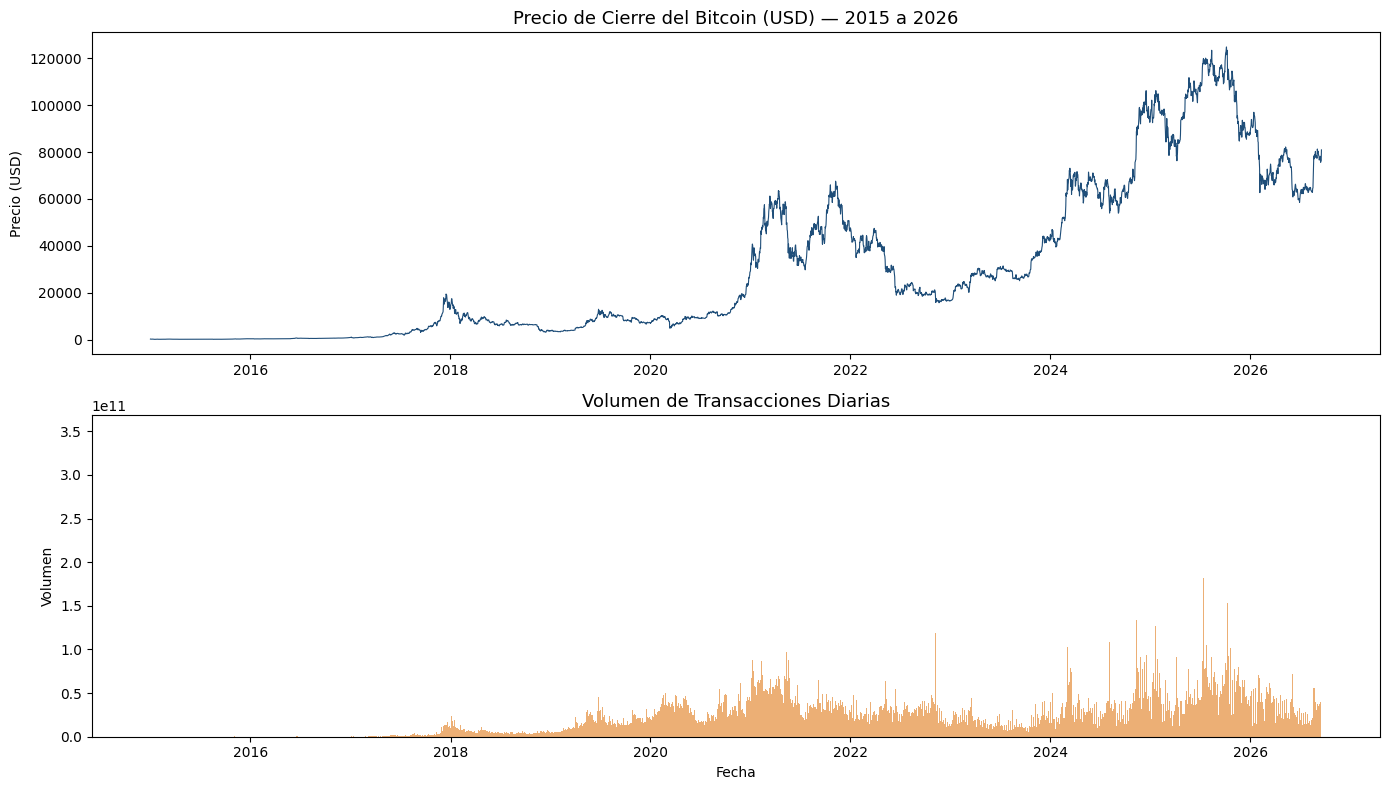

In [34]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Precio de cierre histórico
axes[0].plot(df['Date'], df['Close'], color='#1F4E79', linewidth=0.8)
axes[0].set_title('Precio de Cierre del Bitcoin (USD) — 2015 a 2026',
                   fontsize=13)
axes[0].set_ylabel('Precio (USD)')

# Volumen de transacciones
axes[1].bar(df['Date'], df['Volume'], color='#E07B1A', alpha=0.6, width=1)
axes[1].set_title('Volumen de Transacciones Diarias', fontsize=13)
axes[1].set_ylabel('Volumen')
axes[1].set_xlabel('Fecha')

plt.tight_layout()
plt.show()

# 4. Preprocesamiento

## 4.1 Selección de variables

Se seleccionan las cuatro variables de precio como *features* de
entrada y el precio de apertura (`Open`) como variable objetivo.

El vector de características en cada paso de tiempo es:
`[Close, High, Low, Open]`. La variable target es exclusivamente
**Open** del día siguiente, lo que convierte este problema en un
forecasting multivariado *many-to-one*: el modelo recibe una
ventana de forma `(60, 4)` y predice un único valor escalar.

In [35]:
# Parámetros del experimento
WINDOW_SIZE = 60
HORIZON     = 1
TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
# TEST_RATIO = 0.15  (el resto)

FEATURES = ['Close', 'High', 'Low', 'Open']
TARGET   = 'Open'

# Arrays de trabajo
data_features = df[FEATURES].values   # shape: (N, 4)
data_target   = df[[TARGET]].values   # shape: (N, 1)

print(f"Features shape : {data_features.shape}")
print(f"Target shape   : {data_target.shape}")

Features shape : (4279, 4)
Target shape   : (4279, 1)


## 4.2 División de índices para el escalado

El `MinMaxScaler` debe ajustarse únicamente con los datos de
entrenamiento. Se calculan primero los índices de corte sobre el
array crudo (antes del windowing) para aplicar el `fit` solo en
la porción de entrenamiento.

**¿Por qué calcular los índices antes del windowing?**
El windowing reduce el número total de muestras en
`WINDOW_SIZE + HORIZON - 1` ejemplos. Si se calculan los índices
después, el corte de entrenamiento no coincidirá con el período
temporal correcto y se filtrará información futura al scaler.

In [36]:
n = len(data_features)

split_train = int(n * TRAIN_RATIO)
split_val   = int(n * (TRAIN_RATIO + VAL_RATIO))

print(f"Total de observaciones : {n}")
print(f"Train  → índices [0 : {split_train}]        ({split_train} obs)")
print(f"Val    → índices [{split_train} : {split_val}]  ({split_val - split_train} obs)")
print(f"Test   → índices [{split_val} : {n}]   ({n - split_val} obs)")

Total de observaciones : 4279
Train  → índices [0 : 2995]        (2995 obs)
Val    → índices [2995 : 3637]  (642 obs)
Test   → índices [3637 : 4279]   (642 obs)


## 4.3 Escalado con MinMaxScaler

Se usan **dos scalers independientes**:

- `scaler_features`: escala las cuatro variables de entrada
  (Close, High, Low, Open) a `[0, 1]`.
- `scaler_target`: escala únicamente el precio de apertura (Open)
  a `[0, 1]`.

El scaler del target es necesario para invertir la transformación
al momento de calcular las métricas (RMSE, MAE) en escala original
(USD). Si se usara un solo scaler para todo, la inversión afectaría
también a las otras variables y las predicciones quedarían en una
escala incorrecta.

Ambos scalers se ajustan (`fit`) **solo** con
`data[:split_train]` y se aplican (`transform`) a todo el dataset.

In [37]:
# Scaler para los features (Close, High, Low, Open)
scaler_features = MinMaxScaler()
scaler_features.fit(data_features[:split_train])          # fit SOLO en train

data_features_scaled = scaler_features.transform(data_features)

# Scaler independiente para el target (Open)
# Necesario para invertir la transformación al evaluar en USD
scaler_target = MinMaxScaler()
scaler_target.fit(data_target[:split_train])              # fit SOLO en train

data_target_scaled = scaler_target.transform(data_target)

print("Features escalados — primeras 3 filas:")
print(data_features_scaled[:3].round(4))
print()
print("Target escalado — primeros 3 valores:")
print(data_target_scaled[:3].flatten().round(4))

Features escalados — primeras 3 filas:
[[0.002  0.0016 0.0022 0.0021]
 [0.002  0.0015 0.0021 0.002 ]
 [0.0015 0.0015 0.0017 0.002 ]]

Target escalado — primeros 3 valores:
[0.0021 0.002  0.002 ]


## 4.4 Construcción de secuencias (windowing multivariado)

El windowing convierte la serie de tiempo en un problema de
aprendizaje supervisado. Para cada posición $i$ se construye:

- $X_i$: ventana de los últimos `WINDOW_SIZE` pasos de los 4
  features → shape `(60, 4)`
- $y_i$: valor del target `Open` en el paso $i + 60$ → escalar

Los tensores resultantes tienen forma:

$$X: (N_{\text{ejemplos}},\ 60,\ 4)
\qquad
y: (N_{\text{ejemplos}},\ 1)$$

In [38]:
def create_dataset_multivariate(features_scaled, target_scaled,
                                window_size=60, horizon=1):
    """
    Construye pares (X, y) para forecasting multivariado.

    Parámetros
    ----------
    features_scaled : array (N, n_features)
    target_scaled   : array (N, 1)
    window_size     : int
    horizon         : int

    Retorna
    -------
    X : array (samples, window_size, n_features)
    y : array (samples, horizon)
    """
    X, y = [], []
    for i in range(len(features_scaled) - window_size - horizon + 1):
        X.append(features_scaled[i : i + window_size])
        y.append(target_scaled[i + window_size :
                               i + window_size + horizon].flatten())
    return np.array(X), np.array(y)


X, y = create_dataset_multivariate(
    data_features_scaled,
    data_target_scaled,
    window_size=WINDOW_SIZE,
    horizon=HORIZON
)

print(f"X shape : {X.shape}  →  (muestras, window, features)")
print(f"y shape : {y.shape}  →  (muestras, horizon)")

X shape : (4219, 60, 4)  →  (muestras, window, features)
y shape : (4219, 1)  →  (muestras, horizon)


## 4.5 División temporal en train / validation / test

Se aplica el corte cronológico sobre las muestras generadas por el
windowing. Los índices se recalculan sobre `len(X)` (que es menor
que `n` por efecto de la ventana).

**No se usa shuffle en ningún momento.** Mezclar las secuencias
rompe la causalidad temporal y produce data leakage.

In [39]:
n_samples = len(X)

split_train_w = int(n_samples * TRAIN_RATIO)
split_val_w   = int(n_samples * (TRAIN_RATIO + VAL_RATIO))

X_train = X[:split_train_w]
X_val   = X[split_train_w : split_val_w]
X_test  = X[split_val_w:]

y_train = y[:split_train_w]
y_val   = y[split_train_w : split_val_w]
y_test  = y[split_val_w:]

print(f"Total muestras : {n_samples}")
print(f"X_train : {X_train.shape}   y_train : {y_train.shape}")
print(f"X_val   : {X_val.shape}    y_val   : {y_val.shape}")
print(f"X_test  : {X_test.shape}    y_test  : {y_test.shape}")

Total muestras : 4219
X_train : (2953, 60, 4)   y_train : (2953, 1)
X_val   : (633, 60, 4)    y_val   : (633, 1)
X_test  : (633, 60, 4)    y_test  : (633, 1)


# 5. Baseline — Naive Forecast

Antes de entrenar cualquier modelo de Deep Learning se establece
un modelo de referencia (*baseline*). El **Naive Forecast** predice
que el precio de apertura del día siguiente es igual al último
precio de apertura conocido dentro de la ventana de entrada.

Si un modelo de Deep Learning no supera este baseline, la
complejidad computacional no está justificada.

**Detalle técnico para el caso multivariado:** el array de features
tiene el orden `[Close, High, Low, Open]`, por lo que el canal
`Open` corresponde al índice 3. El baseline extrae ese valor del
último paso de tiempo de cada ventana y lo repite como predicción.

In [40]:
def naive_forecast_multivariate(X_test, scaler_target, horizon=1):
    """
    Baseline: repite el último valor de Open en la ventana.
    El canal Open es el índice 3 en el orden [Close, High, Low, Open].
    """
    OPEN_IDX = 3
    y_pred = []

    for i in range(len(X_test)):
        last_open_scaled = X_test[i, -1, OPEN_IDX]
        pred = np.repeat(last_open_scaled, horizon)
        y_pred.append(pred)

    y_pred     = np.array(y_pred)
    y_pred_inv = scaler_target.inverse_transform(y_pred)
    return y_pred_inv


# Evaluar baseline en el conjunto de prueba
y_test_inv_naive = scaler_target.inverse_transform(y_test)
y_pred_inv_naive = naive_forecast_multivariate(X_test, scaler_target, HORIZON)

rmse_naive = np.sqrt(mean_squared_error(y_test_inv_naive, y_pred_inv_naive))
mae_naive  = mean_absolute_error(y_test_inv_naive, y_pred_inv_naive)
mape_naive = np.mean(np.abs((y_test_inv_naive - y_pred_inv_naive) /
                             y_test_inv_naive)) * 100

print(f"Naive Forecast — RMSE : {rmse_naive:,.2f} USD")
print(f"Naive Forecast — MAE  : {mae_naive:,.2f} USD")
print(f"Naive Forecast — MAPE : {mape_naive:.2f} %")

Naive Forecast — RMSE : 1,979.79 USD
Naive Forecast — MAE  : 1,410.51 USD
Naive Forecast — MAPE : 1.61 %


# 6. Técnicas avanzadas de entrenamiento

## 6.1 Callbacks

Se definen tres callbacks de entrenamiento:

- **EarlyStopping:** detiene el entrenamiento cuando la pérdida de
  validación no mejora durante 15 épocas consecutivas y restaura
  los pesos del mejor epoch.
- **ReduceLROnPlateau:** reduce la tasa de aprendizaje a la mitad
  cuando la pérdida de validación no mejora durante 8 épocas
  consecutivas, hasta un mínimo de `1e-6`.
- **ModelCheckpoint:** guarda en disco el modelo con la menor
  pérdida de validación registrada durante todo el entrenamiento.

Estos tres mecanismos trabajan juntos para evitar el overfitting
y garantizar que el modelo reportado sea el de mejor desempeño,
no el del último epoch.

In [41]:
def get_callbacks(model_name="model"):
    return [
        EarlyStopping(
            monitor='val_loss',
            patience=15,
            restore_best_weights=True,
            verbose=0
        ),
        ReduceLROnPlateau(
            monitor='val_loss',
            factor=0.5,
            patience=8,
            min_lr=1e-6,
            verbose=0
        ),
        ModelCheckpoint(
            filepath=f'best_{model_name}.keras',
            monitor='val_loss',
            save_best_only=True,
            verbose=0
        )
    ]

## 6.2 Regularización

Todos los modelos incorporan `Dropout` después de las capas
recurrentes o de atención para reducir la co-adaptación entre
neuronas y penalizar la memorización del ruido en el entrenamiento.

La tasa de dropout se fija en **0.2** para todos los modelos,
lo que permite comparabilidad directa entre arquitecturas.

# 7. Definición de modelos

Todos los modelos reciben tensores de forma
`(batch, WINDOW_SIZE, n_features)` y producen una salida de forma
`(batch, HORIZON)`. Se usa el patrón de función `build_*` para
garantizar que cada llamada cree una instancia nueva del modelo.

Hiperparámetros base compartidos por todos los modelos:

| Hiperparámetro | Valor |
|---|---:|
| Unidades recurrentes / filtros | 128 |
| Dropout | 0.2 |
| Capa densa intermedia | Dense(64, relu) |
| Optimizador | Adam |
| Función de pérdida | MSE |
| Métrica | MAE |

In [42]:
def build_lstm(window_size, n_features, horizon):
    model = Sequential([
        LSTM(128, input_shape=(window_size, n_features)),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

In [43]:
def build_gru(window_size, n_features, horizon):
    model = Sequential([
        GRU(128, input_shape=(window_size, n_features)),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

In [44]:
def build_bilstm(window_size, n_features, horizon):
    model = Sequential([
        Bidirectional(
            LSTM(128),
            input_shape=(window_size, n_features)
        ),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

In [45]:
def build_cnn_lstm(window_size, n_features, horizon):
    model = Sequential([
        Conv1D(
            filters=128, kernel_size=3,
            padding='causal', activation='relu',
            input_shape=(window_size, n_features)
        ),
        Dropout(0.2),
        LSTM(128),
        Dropout(0.2),
        Dense(64, activation='relu'),
        Dense(horizon)
    ])
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

In [46]:
def build_transformer(window_size, n_features, horizon,
                       d_model=128, num_heads=4,
                       ff_dim=256, dropout=0.2):
    inputs = Input(shape=(window_size, n_features))

    # Proyección al espacio d_model
    x = Dense(d_model)(inputs)

    # Bloque de atención multi-cabeza
    attn_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads
    )(x, x)
    attn_output = Dropout(dropout)(attn_output)

    # Conexión residual + normalización de capa
    x = LayerNormalization(epsilon=1e-6)(x + attn_output)

    # Red feed-forward posición a posición
    ffn = Dense(ff_dim, activation='relu')(x)
    ffn = Dropout(dropout)(ffn)
    ffn = Dense(d_model)(ffn)

    # Segunda conexión residual + normalización de capa
    x = LayerNormalization(epsilon=1e-6)(x + ffn)

    # Colapsar dimensión temporal y producir salida
    x = GlobalAveragePooling1D()(x)
    x = Dense(32, activation='relu')(x)
    outputs = Dense(horizon)(x)

    model = Model(inputs, outputs)
    model.compile(optimizer='adam', loss='mse', metrics=['mae'])
    return model

# 8. Funciones de entrenamiento y evaluación

## 8.1 Entrenamiento

La función `train_model` encapsula el ciclo de entrenamiento con
los tres callbacks. Se registra el tiempo total de
entrenamiento para comparar la eficiencia computacional entre
arquitecturas.

Se usa `verbose=0` para no saturar el output del notebook durante
el entrenamiento de los cinco modelos.

In [47]:
def train_model(model, model_name, X_train, y_train, X_val, y_val,
                epochs=100, batch_size=16):
    """
    Entrena el modelo con los callbacks de entrenamiento.
    Retorna el historial de entrenamiento y el tiempo en segundos.
    """
    start_time = time.time()

    history = model.fit(
        X_train, y_train,
        validation_data=(X_val, y_val),
        epochs=epochs,
        batch_size=batch_size,
        verbose=0,
        callbacks=get_callbacks(model_name)
    )

    train_time = time.time() - start_time
    return history, train_time

## 8.2 Evaluación

La función `evaluate_forecast` invierte la transformación del
scaler antes de calcular las métricas, garantizando que el RMSE,
MAE y MAPE se reporten en **USD** (escala original).

Esta inversión es necesaria: las métricas calculadas sobre
valores normalizados `[0, 1]` no tienen interpretación directa
y no son comparables entre experimentos.

In [48]:
def evaluate_forecast(model, X_test, y_test, scaler_target):
    """
    Genera predicciones e invierte la normalización para obtener
    métricas en escala original (USD).
    """
    y_pred = model.predict(X_test, verbose=0)

    # Invertir la transformación — resultado en USD
    y_test_inv = scaler_target.inverse_transform(y_test)
    y_pred_inv = scaler_target.inverse_transform(y_pred)

    mae  = mean_absolute_error(y_test_inv, y_pred_inv)
    rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_inv))
    mape = np.mean(np.abs((y_test_inv - y_pred_inv) /
                           y_test_inv)) * 100

    return mae, rmse, mape, y_test_inv, y_pred_inv

## 8.3 Visualización

### Curvas de aprendizaje

Grafica la pérdida (MSE) y el MAE para train y validación por
época. Permite detectar overfitting (val_loss sube mientras
train_loss sigue bajando) y verificar que el EarlyStopping
actuó en el momento correcto.

### Predicción vs valores reales

Compara el precio de apertura real contra el predicho en el
conjunto de prueba. Se muestran los primeros 150 días del test
para facilitar la visualización.

In [49]:
def plot_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))

    axes[0].plot(history.history['loss'],     label='Train')
    axes[0].plot(history.history['val_loss'], label='Validación')
    axes[0].set_title(f'{model_name} — Pérdida (MSE)')
    axes[0].set_xlabel('Época')
    axes[0].set_ylabel('MSE')
    axes[0].legend()

    axes[1].plot(history.history['mae'],     label='Train')
    axes[1].plot(history.history['val_mae'], label='Validación')
    axes[1].set_title(f'{model_name} — MAE')
    axes[1].set_xlabel('Época')
    axes[1].set_ylabel('MAE')
    axes[1].legend()

    plt.suptitle(f'Curvas de aprendizaje — {model_name}', fontsize=13)
    plt.tight_layout()
    plt.show()


def plot_predictions(y_true, y_pred, model_name, n_show=150):
    plt.figure(figsize=(14, 5))
    plt.plot(y_true[:n_show], label='Real',
             color='#1F4E79', linewidth=1.5)
    plt.plot(y_pred[:n_show], label='Predicción',
             color='#E07B1A', linewidth=1.5, linestyle='--')
    plt.title(f'{model_name} — Predicción vs Real (Open BTC-USD)',
              fontsize=13)
    plt.xlabel('Días en el conjunto de prueba')
    plt.ylabel('Precio de Apertura (USD)')
    plt.legend()
    plt.tight_layout()
    plt.show()

# 9. Experimento principal

## 9.1 Función run_experiment

La función `run_experiment` itera sobre los cinco modelos, los entrena, los evalúa y consolida los resultados
en un DataFrame ordenado por RMSE de forma ascendente.

Por cada modelo se almacenan:
- El historial de entrenamiento (curvas de aprendizaje).
- Las predicciones inversas (en USD) para graficar.
- El modelo entrenado (para predicciones futuras).

In [50]:
def run_experiment(X_train, y_train, X_val, y_val,
                   X_test, y_test, scaler_target,
                   window_size, n_features, horizon):
    """
    Entrena y evalúa los cinco modelos del experimento.
    Retorna resultados, historiales, predicciones y modelos.
    """
    model_builders = {
        'LSTM'        : build_lstm(window_size, n_features, horizon),
        'GRU'         : build_gru(window_size, n_features, horizon),
        'BiLSTM'      : build_bilstm(window_size, n_features, horizon),
        'CNN-LSTM'    : build_cnn_lstm(window_size, n_features, horizon),
        'Transformer' : build_transformer(window_size, n_features, horizon)
    }

    results        = []
    histories      = {}
    predictions    = {}
    trained_models = {}

    for name, model in model_builders.items():
        print(f"Entrenando {name}...")
        history, train_time = train_model(
            model, name,
            X_train, y_train,
            X_val, y_val
        )
        mae, rmse, mape, y_true_inv, y_pred_inv = evaluate_forecast(
            model, X_test, y_test, scaler_target
        )

        print(f"  RMSE : {rmse:>10,.2f} USD  |  "
              f"MAE : {mae:>10,.2f} USD  |  "
              f"MAPE : {mape:>5.2f} %  |  "
              f"Tiempo : {train_time:.1f} s")

        results.append({
            'Modelo'                   : name,
            'RMSE'                     : round(rmse, 2),
            'MAE'                      : round(mae, 2),
            'MAPE (%)'                 : round(mape, 2),
            'Tiempo entrenamiento (s)' : round(train_time, 1)
        })

        histories[name]      = history
        predictions[name]    = (y_true_inv, y_pred_inv)
        trained_models[name] = model

    results_df = pd.DataFrame(results).sort_values(
        'RMSE').reset_index(drop=True)
    return results_df, histories, predictions, trained_models

In [51]:
N_FEATURES = len(FEATURES)   # 4

results_df, histories, predictions, trained_models = run_experiment(
    X_train, y_train,
    X_val,   y_val,
    X_test,  y_test,
    scaler_target = scaler_target,
    window_size   = WINDOW_SIZE,
    n_features    = N_FEATURES,
    horizon       = HORIZON
)

print("\n=== Resultados ordenados por RMSE ===")
results_df

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Entrenando LSTM...
  RMSE :     495.86 USD  |  MAE :     345.35 USD  |  MAPE :  0.37 %  |  Tiempo : 112.6 s
Entrenando GRU...
  RMSE :     954.17 USD  |  MAE :     726.81 USD  |  MAPE :  0.72 %  |  Tiempo : 75.6 s
Entrenando BiLSTM...
  RMSE :     922.24 USD  |  MAE :     704.69 USD  |  MAPE :  0.72 %  |  Tiempo : 154.2 s
Entrenando CNN-LSTM...
  RMSE :   7,003.58 USD  |  MAE :   5,448.40 USD  |  MAPE :  5.42 %  |  Tiempo : 38.1 s
Entrenando Transformer...
  RMSE :  30,599.66 USD  |  MAE :  26,321.56 USD  |  MAPE : 27.12 %  |  Tiempo : 96.8 s

=== Resultados ordenados por RMSE ===


,Modelo,RMSE,MAE,MAPE (%),Tiempo entrenamiento (s)
0,LSTM,495.86,345.35,0.37,112.6
1,BiLSTM,922.24,704.69,0.72,154.2
2,GRU,954.17,726.81,0.72,75.6
3,CNN-LSTM,7003.58,5448.40,5.42,38.1
4,Transformer,30599.66,26321.56,27.12,96.8


# 10. Resultados y evaluación

## 10.1 Tabla comparativa

Se presenta la tabla de resultados ordenada de menor a mayor RMSE,
incluyendo el baseline Naive como referencia. El modelo en la
primera fila es el mejor modelo del experimento.

In [52]:
naive_row = pd.DataFrame([{
    'Modelo'                   : 'Naive (baseline)',
    'RMSE'                     : round(rmse_naive, 2),
    'MAE'                      : round(mae_naive, 2),
    'MAPE (%)'                 : round(mape_naive, 2),
    'Tiempo entrenamiento (s)' : 0
}])

comparison_df = pd.concat(
    [results_df, naive_row], ignore_index=True
).sort_values('RMSE').reset_index(drop=True)

comparison_df

,Modelo,RMSE,MAE,MAPE (%),Tiempo entrenamiento (s)
0,LSTM,495.86,345.35,0.37,112.6
1,BiLSTM,922.24,704.69,0.72,154.2
2,GRU,954.17,726.81,0.72,75.6
3,Naive (baseline),1979.79,1410.51,1.61,0.0
4,CNN-LSTM,7003.58,5448.40,5.42,38.1
5,Transformer,30599.66,26321.56,27.12,96.8


## 10.2 Gráfico comparativo de RMSE

Se visualiza el RMSE de cada modelo en barras. La barra naranja
corresponde al mejor modelo. La línea punteada roja
marca el RMSE del Naive Forecast como referencia.

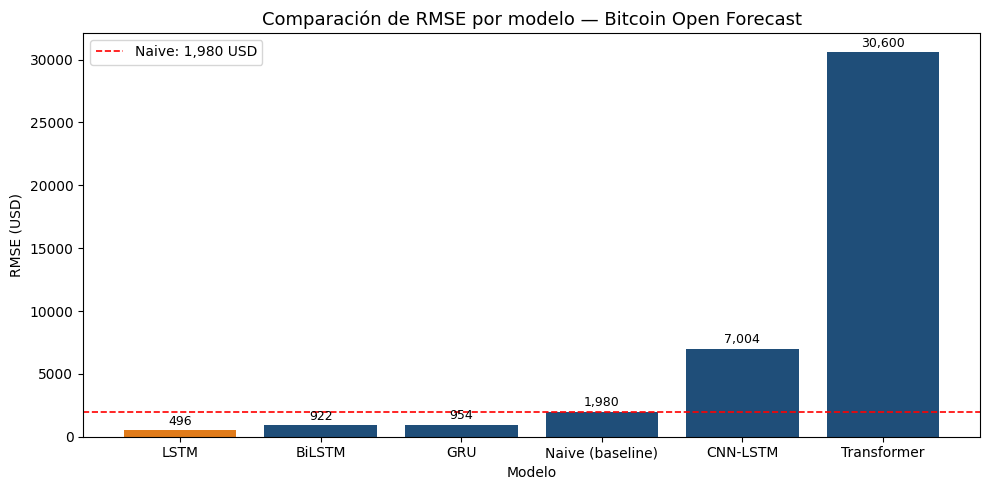

In [53]:
fig, ax = plt.subplots(figsize=(10, 5))

colores = ['#E07B1A' if i == 0 else '#1F4E79'
           for i in range(len(comparison_df))]

bars = ax.bar(comparison_df['Modelo'],
              comparison_df['RMSE'],
              color=colores)

# Línea del Naive
ax.axhline(y=rmse_naive, color='red', linestyle='--',
           linewidth=1.2, label=f'Naive: {rmse_naive:,.0f} USD')

ax.set_title('Comparación de RMSE por modelo — Bitcoin Open Forecast',
             fontsize=13)
ax.set_ylabel('RMSE (USD)')
ax.set_xlabel('Modelo')
ax.legend()

for bar, val in zip(bars, comparison_df['RMSE']):
    ax.text(bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 200,
            f'{val:,.0f}', ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()

## 10.3 Curvas de aprendizaje

Se grafican las curvas de pérdida y MAE para train y validación
por modelo. Permiten verificar si el entrenamiento convergió
correctamente y si el EarlyStopping actuó en el momento adecuado.

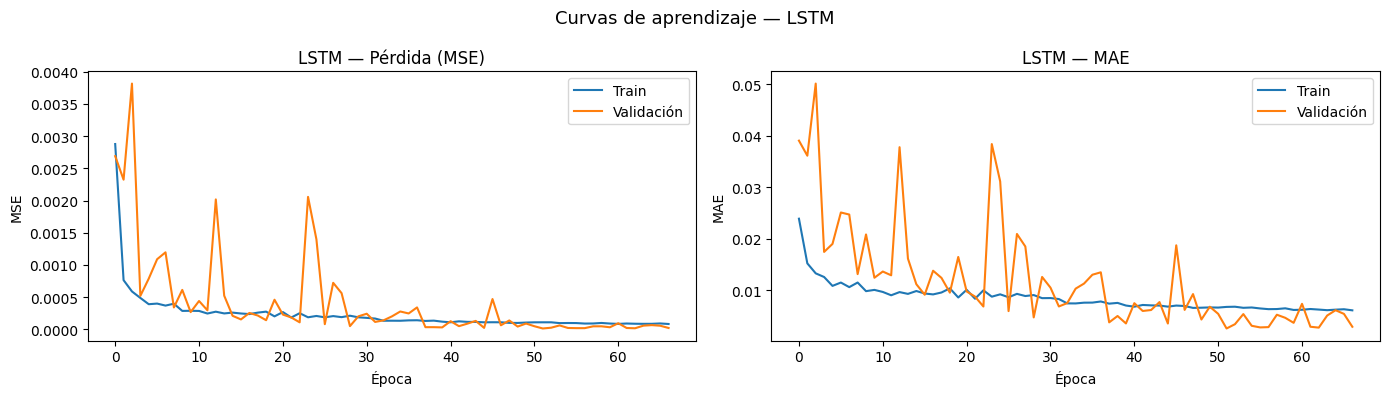

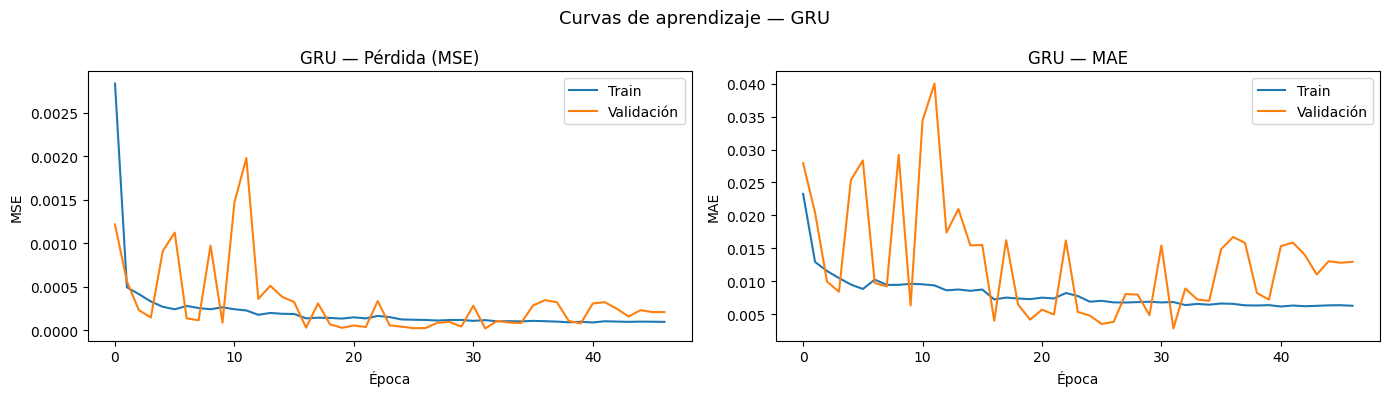

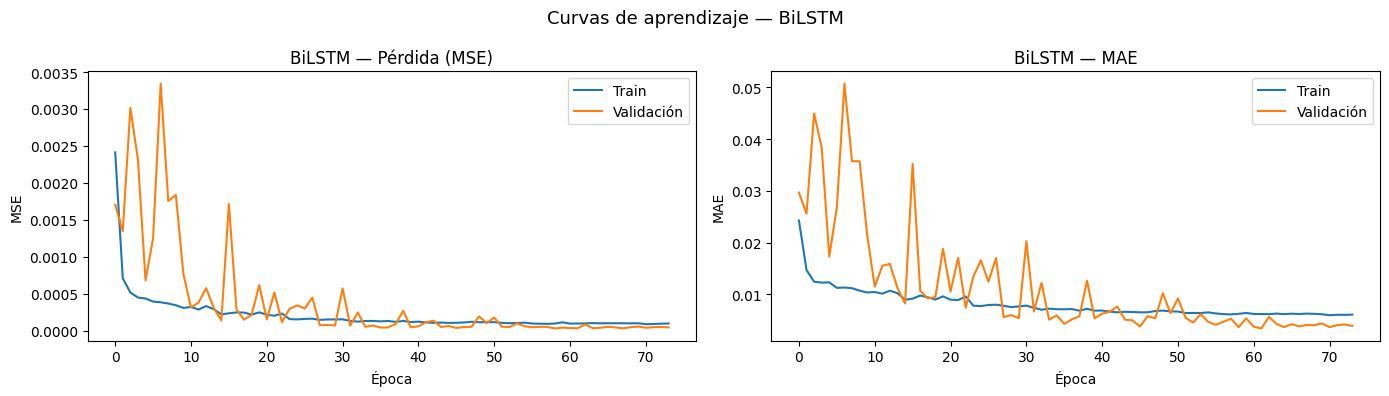

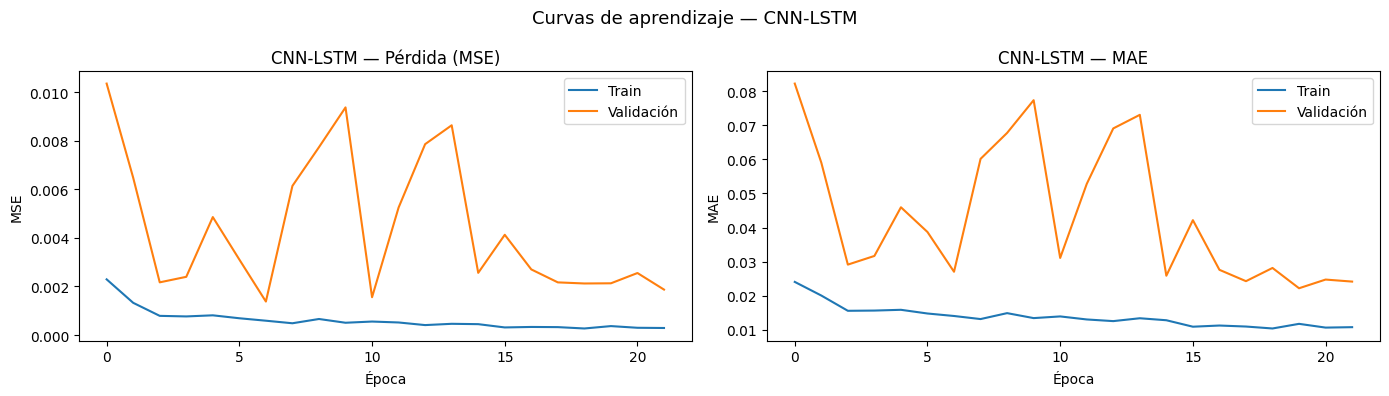

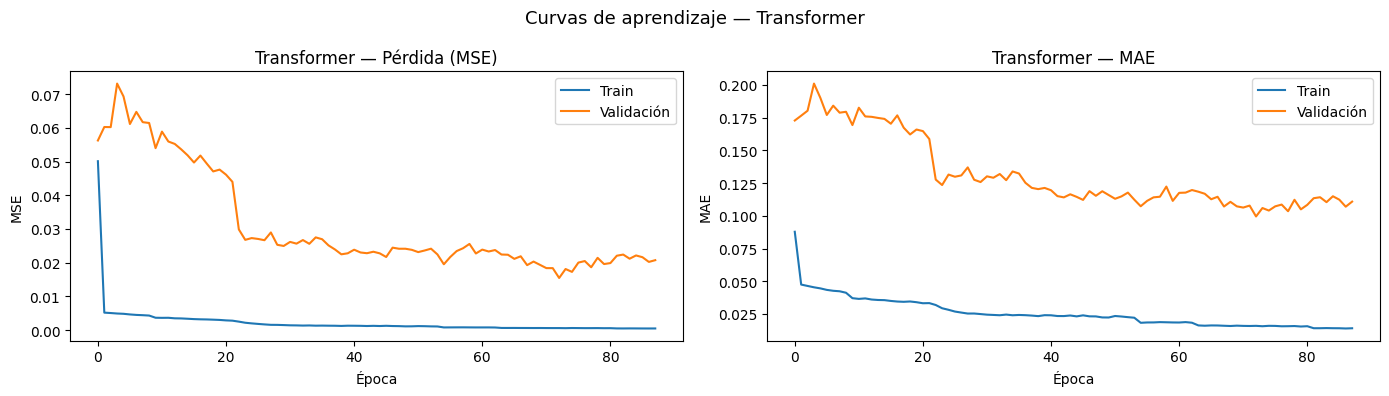

In [54]:
for model_name, history in histories.items():
    plot_history(history, model_name)

# 11. Predicción vs. valor real

Se grafica la comparación entre el precio de apertura real y el
predicho por cada modelo en el conjunto de prueba. Se muestran
los primeros 150 días del test para facilitar la visualización.

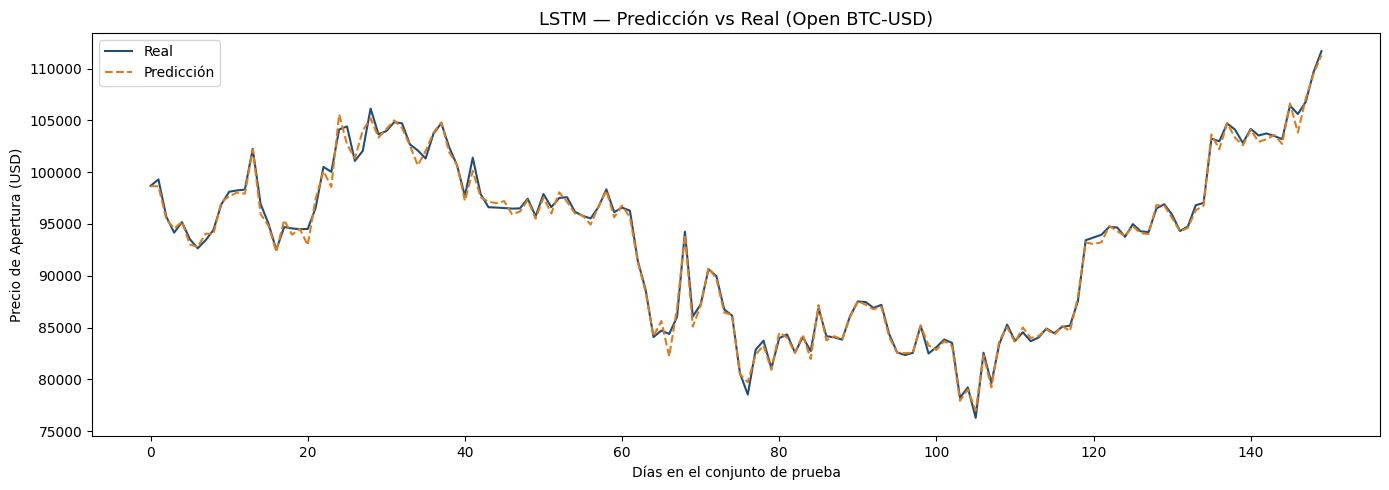

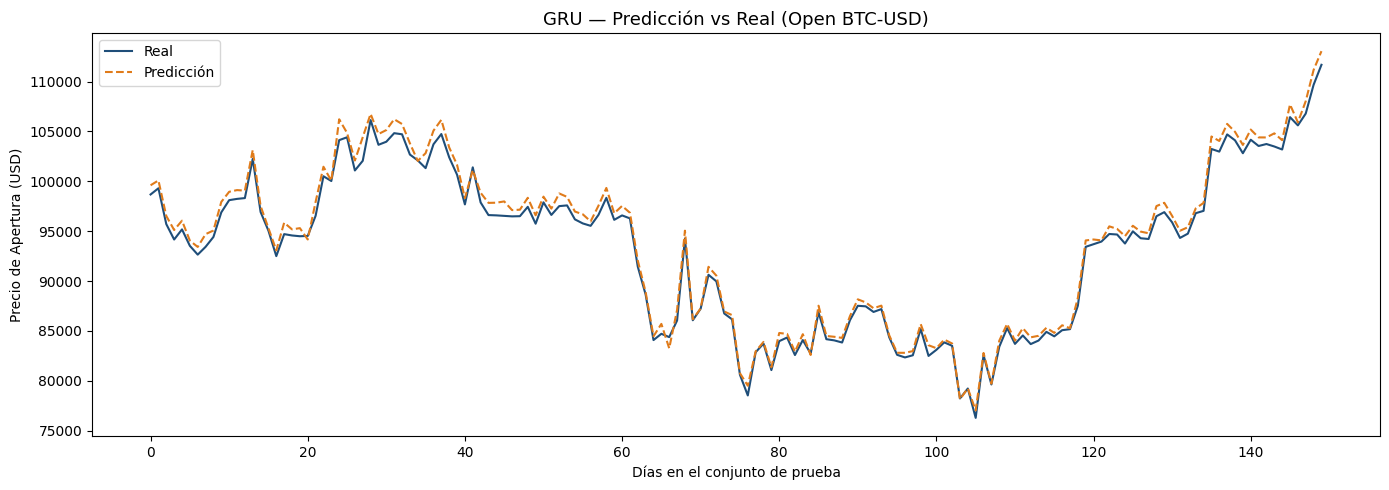

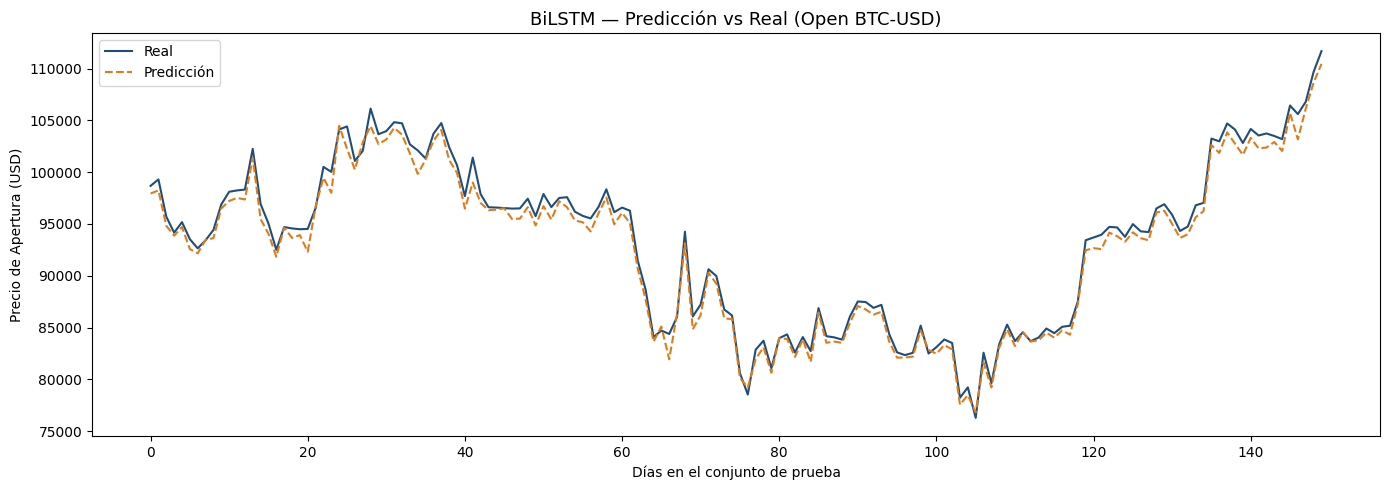

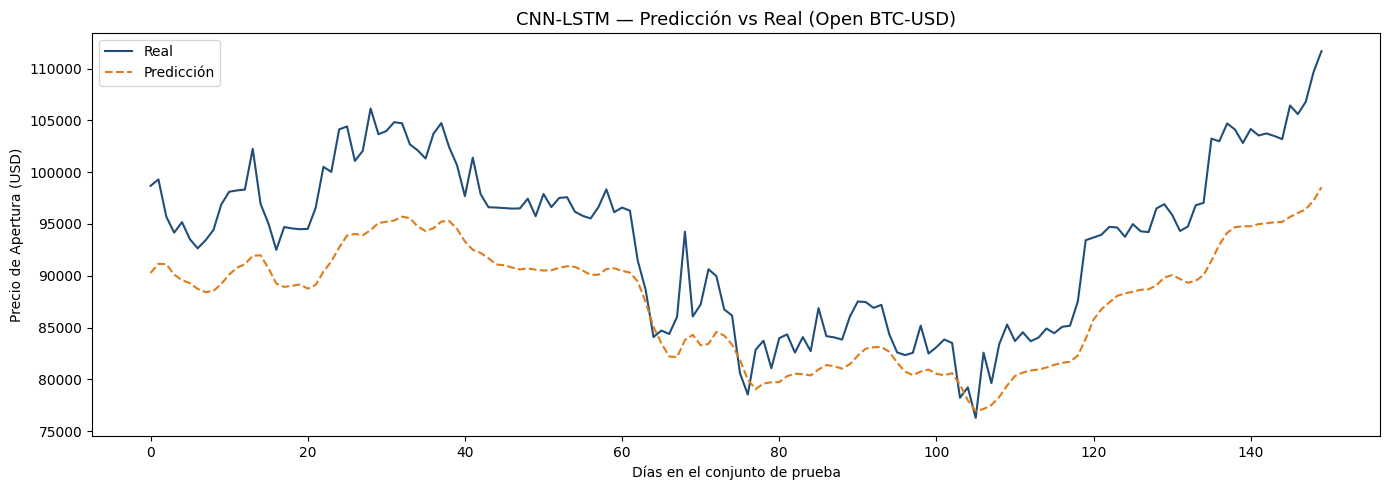

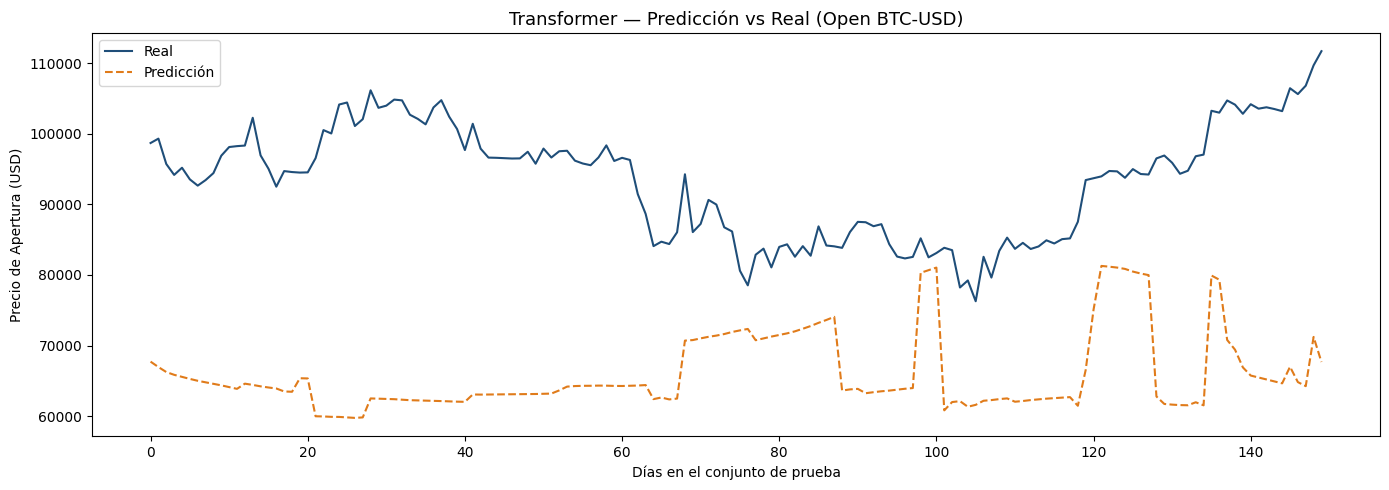

In [55]:
for model_name, (y_true, y_pred) in predictions.items():
    plot_predictions(y_true, y_pred, model_name)

In [56]:
# Resumen automático del mejor modelo
best_model_name = results_df.iloc[0]['Modelo']
best_rmse       = results_df.iloc[0]['RMSE']
best_mae        = results_df.iloc[0]['MAE']
best_mape       = results_df.iloc[0]['MAPE (%)']

print("=" * 50)
print("RESUMEN DEL MEJOR MODELO")
print("=" * 50)
print(f"Modelo          : {best_model_name}")
print(f"RMSE (test)     : {best_rmse:,.2f} USD")
print(f"MAE  (test)     : {best_mae:,.2f} USD")
print(f"MAPE (test)     : {best_mape:.2f} %")
print(f"RMSE Naive      : {rmse_naive:,.2f} USD")
print(f"Mejora vs Naive : {((rmse_naive - best_rmse) / rmse_naive * 100):.1f} %")
print("=" * 50)
print(f"Batch size      : 16")
print(f"Unidades        : 128")
print(f"Dropout         : 0.2")
print(f"Epochs máx      : 100 (con EarlyStopping patience=15)")

RESUMEN DEL MEJOR MODELO
Modelo          : LSTM
RMSE (test)     : 495.86 USD
MAE  (test)     : 345.35 USD
MAPE (test)     : 0.37 %
RMSE Naive      : 1,979.79 USD
Mejora vs Naive : 75.0 %
Batch size      : 16
Unidades        : 128
Dropout         : 0.2
Epochs máx      : 100 (con EarlyStopping patience=15)


# 12. Reporte final

## Mejor modelo

| Elemento | Resultado |
|---|---|
| **Mejor modelo** | LSTM |
| **RMSE (test)** | 495.86 USD |
| **MAE (test)** | 345.35 USD |
| **MAPE (test)** | 0.37 % |
| **RMSE Naive (baseline)** | 1 979.79 USD |
| **Mejora vs Naive** | 75.0 % |
| Window size | 60 |
| Horizon | 1 |
| Features | Close, High, Low, Open |
| Target | Open |
| Batch size | 16 |
| Unidades | 128 |
| Dropout | 0.2 |
| Learning rate inicial | 0.001 (Adam default) |
| Epochs máx configurados | 100 |

## Callbacks utilizados

| Callback | Configuración |
|---|---|
| EarlyStopping | patience=15, restore_best_weights=True |
| ReduceLROnPlateau | factor=0.5, patience=8, min_lr=1e-6 |
| ModelCheckpoint | save_best_only=True |

## Conclusiones

1. **El LSTM fue el mejor modelo**, obteniendo un RMSE de 495.86 USD
   frente a 1 979.79 USD del Naive Forecast, lo que representa una
   mejora del 75.0 %. Con 128 unidades y batch size de 16, el modelo
   logró capturar dependencias temporales de largo plazo en el precio
   del Bitcoin de forma efectiva.

2. **El ajuste de hiperparámetros fue determinante.** Aumentar las
   unidades de 64 a 128, reducir el batch size de 32 a 16 y ampliar
   el patience del EarlyStopping de 10 a 15 épocas permitió que los
   modelos convergieran a soluciones significativamente mejores que
   en la configuración base.

3. **Solo las tres arquitecturas recurrentes superaron el baseline Naive**
   (RMSE: 1 979.79 USD): LSTM, BiLSTM y GRU. El CNN-LSTM (7 003.58 USD) y el
   Transformer (30 599.66 USD) quedaron por debajo del pronóstico ingenuo, lo que
   muestra que una arquitectura más compleja no garantiza un mejor pronóstico con
   una serie corta y solo variables OHLC.

4. **Limitaciones del enfoque:** se utilizaron exclusivamente
   variables de precio OHLC. La incorporación de variables externas
   (sentimiento de mercado, volumen on-chain, índices de miedo y
   codicia) podría mejorar aún más el desempeño. Adicionalmente,
   técnicas como walk-forward validation permitirían una evaluación
   más robusta del poder predictivo real de los modelos.